In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
np.random.seed(42)

In [2]:
df = pd.read_csv("act1_student_performance_raw.csv")

df.head()

,student_id,school,age,Medu,Fedu,study_time,failures,school_support,internet_access,absences,G1,G2,final_grade
0,STU_1000,GP,17.0,0,1,3.0,0,no,yes,21,13.0,17.0,13.0
1,STU_1001,MS,15.0,0,1,2.0,0,no,no,21,7.0,10.0,7.0
2,STU_1002,MS,NaN,0,1,2.0,0,no,yes,6,11.0,10.0,15.0
3,STU_1003,GP,18.0,3,2,2.0,0,no,no,9,12.0,9.0,16.0
4,STU_1004,GP,17.0,0,2,2.0,0,no,yes,0,15.0,13.0,11.0


In [3]:
print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (203, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 203 entries, 0 to 202
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       203 non-null    object 
 1   school           203 non-null    object 
 2   age              186 non-null    float64
 3   Medu             203 non-null    int64  
 4   Fedu             203 non-null    int64  
 5   study_time       191 non-null    float64
 6   failures         203 non-null    int64  
 7   school_support   203 non-null    object 
 8   internet_access  193 non-null    object 
 9   absences         203 non-null    int64  
 10  G1               203 non-null    float64
 11  G2               203 non-null    float64
 12  final_grade      203 non-null    float64
dtypes: float64(5), int64(4), object(4)
memory usage: 20.7+ KB


In [4]:
display(df.describe())

,age,Medu,Fedu,study_time,failures,absences,G1,G2,final_grade
count,186.000000,203.000000,203.000000,191.000000,203.000000,203.000000,203.000000,203.000000,203.000000
mean,16.575269,2.098522,1.896552,2.094241,0.443350,8.640394,10.911330,10.975369,11.576355
std,1.128132,1.518907,1.383831,0.946750,0.814772,8.896197,2.899645,2.935677,3.473782
min,15.000000,0.000000,0.000000,1.000000,0.000000,0.000000,2.000000,3.000000,2.000000
25%,16.000000,1.000000,1.000000,1.000000,0.000000,2.000000,9.000000,9.000000,9.000000
50%,17.000000,2.000000,2.000000,2.000000,0.000000,6.000000,11.000000,11.000000,11.000000
75%,17.000000,4.000000,3.000000,3.000000,1.000000,12.000000,13.000000,13.000000,14.000000
max,19.000000,4.000000,4.000000,4.000000,3.000000,59.000000,19.000000,20.000000,20.000000


In [6]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical Columns:", num_cols)
print("Categorical Columns:", cat_cols)

Numerical Columns: ['age', 'Medu', 'Fedu', 'study_time', 'failures', 'absences', 'G1', 'G2', 'final_grade']
Categorical Columns: ['student_id', 'school', 'school_support', 'internet_access']


In [7]:
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing_summary)

,Missing Count,Missing Percentage
student_id,0,0.00
school,0,0.00
age,17,8.37
Medu,0,0.00
Fedu,0,0.00
study_time,12,5.91
failures,0,0.00
school_support,0,0.00
internet_access,10,4.93
absences,0,0.00


In [8]:
df_cleaned = df.copy()

for col in num_cols:
    df_cleaned[col] = df_cleaned[col].fillna(df_cleaned[col].median())

for col in cat_cols:
    df_cleaned[col] = df_cleaned[col].fillna(df_cleaned[col].mode()[0])

print("Remaining Missing Values:", df_cleaned.isnull().sum().sum())

Remaining Missing Values: 0


In [9]:
print("Duplicates Found:", df_cleaned.duplicated().sum())

df_cleaned = df_cleaned.drop_duplicates().reset_index(drop=True)

print("Shape After Removing Duplicates:", df_cleaned.shape)

Duplicates Found: 3
Shape After Removing Duplicates: (200, 13)


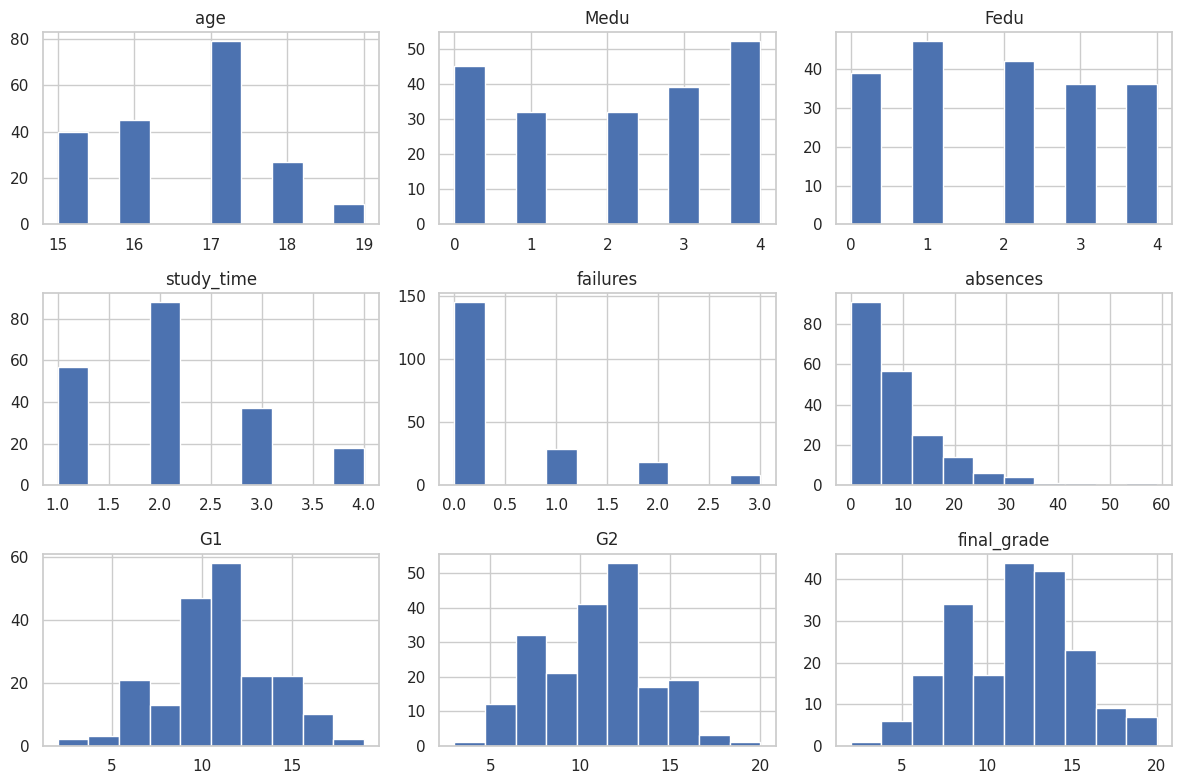

In [10]:
df_cleaned.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

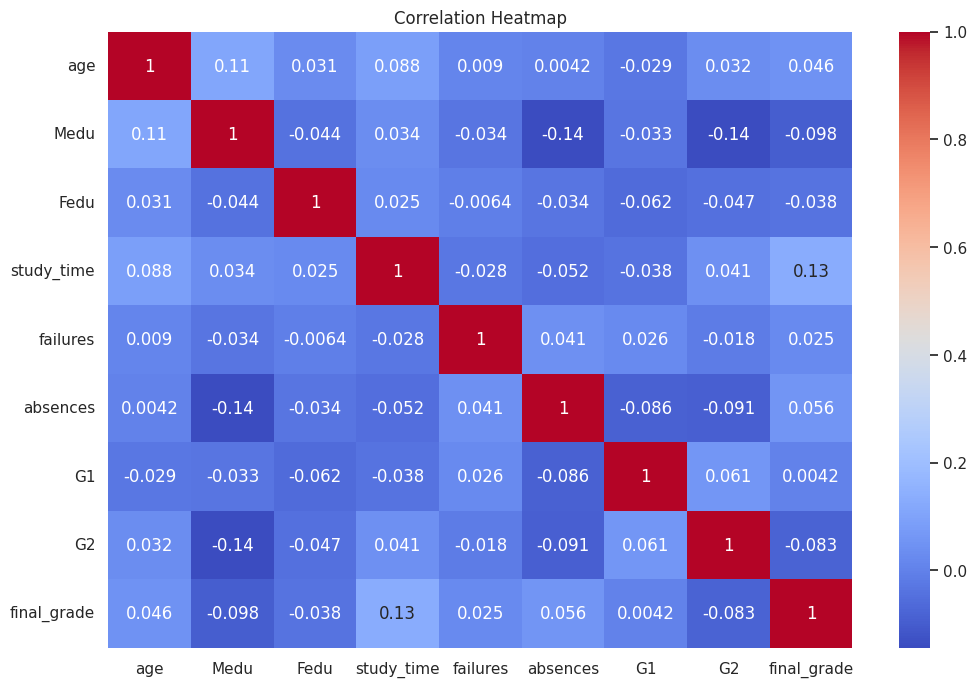

In [11]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_cleaned.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()

In [12]:
df_prep = pd.get_dummies(
    df_cleaned,
    drop_first=True,
    dtype=int
)

display(df_prep.head())

,age,Medu,Fedu,study_time,failures,absences,G1,G2,final_grade,student_id_STU_1001,...,student_id_STU_1193,student_id_STU_1194,student_id_STU_1195,student_id_STU_1196,student_id_STU_1197,student_id_STU_1198,student_id_STU_1199,school_MS,school_support_yes,internet_access_yes
0,17.0,0,1,3.0,0,21,13.0,17.0,13.0,0,...,0,0,0,0,0,0,0,0,0,1
1,15.0,0,1,2.0,0,21,7.0,10.0,7.0,1,...,0,0,0,0,0,0,0,1,0,0
2,17.0,0,1,2.0,0,6,11.0,10.0,15.0,0,...,0,0,0,0,0,0,0,1,0,1
3,18.0,3,2,2.0,0,9,12.0,9.0,16.0,0,...,0,0,0,0,0,0,0,0,0,0
4,17.0,0,2,2.0,0,0,15.0,13.0,11.0,0,...,0,0,0,0,0,0,0,0,0,1


In [13]:
scale_cols = df_prep.select_dtypes(include=np.number).columns

scaler = StandardScaler()

df_prep[scale_cols] = scaler.fit_transform(df_prep[scale_cols])

print("Feature Scaling Completed")

Feature Scaling Completed


In [14]:
df_prep.to_csv("student_performance_prepared.csv", index=False)

print("Prepared Dataset Exported Successfully")
print("Final Shape:", df_prep.shape)

display(df_prep.head())

Prepared Dataset Exported Successfully
Final Shape: (200, 211)


,age,Medu,Fedu,study_time,failures,absences,G1,G2,final_grade,student_id_STU_1001,...,student_id_STU_1193,student_id_STU_1194,student_id_STU_1195,student_id_STU_1196,student_id_STU_1197,student_id_STU_1198,student_id_STU_1199,school_MS,school_support_yes,internet_access_yes
0,0.368230,-1.392857,-0.662457,1.013747,-0.544885,1.382184,0.717942,2.040134,0.404394,-0.070888,...,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.654654,-0.51558,0.492175
1,-1.472919,-1.392857,-0.662457,-0.088152,-0.544885,1.382184,-1.353044,-0.342007,-1.322557,14.106736,...,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,1.527525,-0.51558,-2.031798
2,0.368230,-1.392857,-0.662457,-0.088152,-0.544885,-0.298624,0.027613,-0.342007,0.980045,-0.070888,...,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,1.527525,-0.51558,0.492175
3,1.288804,0.592212,0.061540,-0.088152,-0.544885,0.037538,0.372777,-0.682313,1.267870,-0.070888,...,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.654654,-0.51558,-2.031798
4,0.368230,-1.392857,0.061540,-0.088152,-0.544885,-0.970947,1.408270,0.678910,-0.171256,-0.070888,...,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.070888,-0.654654,-0.51558,0.492175
